# Stress Estimation Framework — TensorFlow/Keras
### CMU-MOSEI Proxy-Based Multimodal Stress Detection

In [ ]:
# CELL 1 — Mount Drive & install dependencies
from google.colab import drive
drive.mount('/content/drive')

import subprocess
subprocess.run(['pip', 'install', '-q',
    'pyarrow', 'scikit-learn', 'librosa',
    'transformers', 'accelerate', 'bitsandbytes'])

Mounted at /content/drive


CompletedProcess(args=['pip', 'install', '-q', 'pyarrow', 'scikit-learn', 'librosa', 'transformers', 'accelerate', 'bitsandbytes'], returncode=0)

In [ ]:
# CELL 2 — Upload framework files OR clone from your repo
# If files are in Drive already:
import sys, os
FRAMEWORK_DIR = '/content/drive/MyDrive/stress_framework'
sys.path.insert(0, FRAMEWORK_DIR)
os.chdir(FRAMEWORK_DIR)
print('Working directory:', os.getcwd())

Working directory: /content/drive/MyDrive/stress_framework


In [ ]:
# CELL 3 — Verify GPU
import tensorflow as tf
print('TF version :', tf.__version__)
print('GPUs found :', tf.config.list_physical_devices('GPU'))

TF version : 2.19.0
GPUs found : []


In [ ]:
# CELL 4 — Load & inspect the dataset
from preprocessing import load_parquet
df = load_parquet()
print(df.shape)
print(df.columns.tolist())
print(df.head(3))

(23248, 12)
['video_id', 'segment_id', 'sentiment', 'text_emb', 'visual_emb', 'audio_emb', 'label_happy', 'label_sad', 'label_anger', 'label_surprise', 'label_disgust', 'label_fear']
      video_id  segment_id  sentiment  \
0  --qXJuDtHPw           0   1.000000   
1  -3g5yACwYnA           0   1.000000   
2  -3g5yACwYnA           1   0.666667   

                                            text_emb  \
0  [-0.00437335, 0.1540662, -0.10662533, -0.00447...   
1  [0.0032292067, 0.12673105, -0.1463835, -0.0180...   
2  [-0.067196, 0.12256045, -0.23286165, -0.007806...   

                                          visual_emb  \
0  [0.0, 26.766666, 0.91262895, 1.0, 0.20842315, ...   
1  [0.0, 91.66667, 0.9800043, 1.0, 0.18150234, 0....   
2  [0.0, 122.61666, 0.9800004, 1.0, 0.18440922, 0...   

                                           audio_emb  label_happy  label_sad  \
0  [114.974014, 0.56882024, 0.042089444, 0.135645...     0.666667   0.000000   
1  [117.20714, 0.5503092, 0.08181889, 0.39

In [ ]:
# ── FIX CELL v2 — replace previous fix cell entirely ─────────────────────────
import numpy as np

def fix_dataframe(df):

    # ── 1. Auto-detect and patch actual dimensions into config ────────────────
    import config
    config.TEXT_DIM   = np.vstack(df["text_emb"].values[:1]).shape[1]
    config.AUDIO_DIM  = np.vstack(df["audio_emb"].values[:1]).shape[1]
    config.VISUAL_DIM = np.vstack(df["visual_emb"].values[:1]).shape[1]
    print(f"Dims — text:{config.TEXT_DIM}  "
          f"audio:{config.AUDIO_DIM}  visual:{config.VISUAL_DIM}")

    # ── 2. Per-column cleaning strategy ──────────────────────────────────────
    # text_emb  → already clean, just cast
    # audio_emb → has inf, use median fill + 3-std clip
    # visual_emb → extreme outliers, use percentile clip (robust to huge std)

    strategies = {
        "text_emb":   "std",
        "audio_emb":  "std",
        "visual_emb": "percentile",
    }

    for col, strategy in strategies.items():

        arr = np.vstack(df[col].values).astype(np.float64)

        # Step 1 — replace inf with NaN
        n_inf = int(np.isinf(arr).sum())
        arr[np.isinf(arr)] = np.nan

        # Step 2 — fill NaN with column-wise median
        n_nan = int(np.isnan(arr).sum())
        if n_inf + n_nan > 0:
            print(f"{col}: fixing {n_inf} inf + {n_nan} nan values")
            col_medians        = np.nanmedian(arr, axis=0)
            nan_rows, nan_cols = np.where(np.isnan(arr))
            arr[nan_rows, nan_cols] = col_medians[nan_cols]

        # Step 3 — clip outliers
        if strategy == "percentile":
            # Clip each feature to its 1st–99th percentile range
            # Robust even when std is millions
            p01 = np.percentile(arr, 1,  axis=0)
            p99 = np.percentile(arr, 99, axis=0)
            arr = np.clip(arr, p01, p99)
            print(f"{col}: percentile clip applied")

        else:  # std-based
            mean = arr.mean(axis=0)
            std  = arr.std(axis=0)
            std[std == 0] = 1.0
            arr  = np.clip(arr, mean - 3*std, mean + 3*std)

        # Step 4 — safe float32 cast
        arr = arr.astype(np.float32)

        # Verify
        assert not np.isinf(arr).any(), f"inf remains in {col}"
        assert not np.isnan(arr).any(), f"nan remains in {col}"

        df[col] = list(arr)
        print(f"{col}: done — min={arr.min():.4f}  max={arr.max():.4f}")

    return df

# Apply
df = fix_dataframe(df)
print("\nAll clean. Run Cell 5 now.")

Dims — text:300  audio:74  visual:713
text_emb: done — min=-2.1291  max=2.8965
audio_emb: fixing 1223 inf + 1223 nan values
audio_emb: done — min=-10.4286  max=329.9527
visual_emb: percentile clip applied
visual_emb: done — min=-29746722.0000  max=40801192.0000

All clean. Run Cell 5 now.


In [ ]:
# ── DIAGNOSTIC CELL — run this before Cell 5 ──────────────────────────────
import numpy as np

emb_cols = ["text_emb", "visual_emb", "audio_emb"]

for col in emb_cols:
    arr = np.vstack(df[col].values).astype(np.float64)  # float64 to catch large values
    n_inf  = int(np.isinf(arr).sum())
    n_nan  = int(np.isnan(arr).sum())
    n_huge = int((np.abs(arr) > 1e10).sum())
    print(f"\n{col}")
    print(f"  shape  : {arr.shape}")
    print(f"  dtype  : {arr.dtype}")
    print(f"  min    : {arr[np.isfinite(arr)].min():.4f}")
    print(f"  max    : {arr[np.isfinite(arr)].max():.4f}")
    print(f"  n_inf  : {n_inf}")
    print(f"  n_nan  : {n_nan}")
    print(f"  n_huge : {n_huge}  (|value| > 1e10)")

print("\nlabel_anger:", df["label_anger"].describe())
print("\nlabel_fear :", df["label_fear"].describe())


text_emb
  shape  : (23248, 300)
  dtype  : float64
  min    : -2.1291
  max    : 2.8965
  n_inf  : 0
  n_nan  : 0
  n_huge : 0  (|value| > 1e10)

visual_emb
  shape  : (23248, 713)
  dtype  : float64
  min    : -29746722.0000
  max    : 40801192.0000
  n_inf  : 0
  n_nan  : 0
  n_huge : 0  (|value| > 1e10)

audio_emb
  shape  : (23248, 74)
  dtype  : float64
  min    : -10.4286
  max    : 329.9527
  n_inf  : 0
  n_nan  : 0
  n_huge : 0  (|value| > 1e10)

label_anger: count    23248.000000
mean         0.155727
std          0.362184
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          3.000000
Name: label_anger, dtype: float64

label_fear : count    23248.000000
mean         0.041000
std          0.152557
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.666667
Name: label_fear, dtype: float64


In [ ]:
# CELL 5 — Build datasets (split + normalise)
from preprocessing import build_datasets
train_ds, val_ds, test_ds, scaler, df_test, arrays = build_datasets(df)
print('train_ds batches:', len(train_ds))
print('val_ds   batches:', len(val_ds))
print('test_ds  batches:', len(test_ds))

train_ds batches: 509
val_ds   batches: 73
test_ds  batches: 146


In [ ]:
# ── RELOAD CELL — run this, then re-run Cell 6 ───────────────────────────────
import importlib, sys

# Remove all cached framework modules
modules_to_remove = [k for k in sys.modules
                     if k in ("models", "train", "evaluate",
                               "preprocessing", "config",
                               "stress_score", "intervention", "main")]
for m in modules_to_remove:
    del sys.modules[m]
    print(f"Cleared: {m}")

# Re-import from the updated files on Drive
import config
import models
from models import build_model
from config import MODEL_NAMES, FUSION_STRATEGIES

print("\nReloaded. Keras version:", __import__("keras").__version__)
print("TF version:", __import__("tensorflow").__version__)

Cleared: config
Cleared: preprocessing

Reloaded. Keras version: 3.10.0
TF version: 2.19.0


In [ ]:
# ── PATCH CELL — run this, then re-run Cell 6 ────────────────────────────────
import sys, types

# Get the already-loaded models module
import models

# Patch build_tfn with fusion-aware names
def build_tfn(fusion: str = "early"):
    import keras
    from keras import layers, ops
    from models import (AppendOne, TFNOuterProduct, modality_projector,
                        regression_head, late_fuse, L2)
    from config import TEXT_DIM, AUDIO_DIM, VISUAL_DIM, COMMON_DIM, DROPOUT

    f = fusion  # short alias for names
    inp_t = keras.Input(shape=(TEXT_DIM,),   name="text")
    inp_a = keras.Input(shape=(AUDIO_DIM,),  name="audio")
    inp_v = keras.Input(shape=(VISUAL_DIM,), name="visual")

    pt = modality_projector(inp_t, f"tfn_{f}_t")
    pa = modality_projector(inp_a, f"tfn_{f}_a")
    pv = modality_projector(inp_v, f"tfn_{f}_v")

    if fusion in ("early", "cross_modal"):
        SUB = 16
        st = layers.Dense(SUB, activation="tanh", name=f"tfn_{f}_sub_t")(pt)
        sa = layers.Dense(SUB, activation="tanh", name=f"tfn_{f}_sub_a")(pa)
        sv = layers.Dense(SUB, activation="tanh", name=f"tfn_{f}_sub_v")(pv)

        ht = AppendOne(name=f"tfn_{f}_ht")(st)
        ha = AppendOne(name=f"tfn_{f}_ha")(sa)
        hv = AppendOne(name=f"tfn_{f}_hv")(sv)

        fused = TFNOuterProduct(name=f"tfn_{f}_outer")([ht, ha, hv])
        fused = layers.Dense(256, activation="relu",
                             kernel_regularizer=L2,
                             name=f"tfn_{f}_fc1")(fused)
        fused = layers.BatchNormalization(name=f"tfn_{f}_fc1_bn")(fused)
        fused = layers.Dropout(DROPOUT, name=f"tfn_{f}_fc1_drop")(fused)
        fused = layers.Dense(COMMON_DIM, activation="relu",
                             name=f"tfn_{f}_fc2")(fused)
    else:
        fused = late_fuse(pt, pa, pv, f"tfn_{f}")

    out = keras.layers.Dense(64, activation="relu",
                              name=f"tfn_{f}_head_fc1")(fused)
    out = keras.layers.BatchNormalization(name=f"tfn_{f}_head_bn")(out)
    out = keras.layers.Dropout(DROPOUT, name=f"tfn_{f}_head_drop")(out)
    out = keras.layers.Dense(2, name=f"tfn_{f}_out")(out)

    return keras.Model(inputs=[inp_t, inp_a, inp_v],
                       outputs=out, name=f"TFN_{fusion}")

# Monkey-patch into the loaded module
models.build_tfn = build_tfn
models._BUILDERS["TFN"] = build_tfn

print("TFN patched with fusion-aware layer names.")

TFN patched with fusion-aware layer names.


In [ ]:
import sys
for m in list(sys.modules.keys()):
    if m in ('models', 'config', 'train', 'preprocessing'):
        del sys.modules[m]

import models
from models import build_model
from config import MODEL_NAMES, FUSION_STRATEGIES
print("Reloaded")

Reloaded


In [ ]:
# ── PATCH LMFFusionLayer.build() for Keras 3 ─────────────────────────────────
import models
from keras import ops
import keras

class LMFFusionLayerFixed(keras.layers.Layer):
    def __init__(self, rank=4, out_dim=32, **kwargs):
        super().__init__(**kwargs)
        self.rank    = rank
        self.out_dim = out_dim

    def build(self, input_shape):
        d    = input_shape[0][-1]
        init = keras.initializers.GlorotUniform()
        # Keras 3: add_weight(shape=..., name=...) — name must be keyword
        self.ft = self.add_weight(shape=(self.rank, d, self.out_dim),
                                  name="ft", initializer=init)
        self.fa = self.add_weight(shape=(self.rank, d, self.out_dim),
                                  name="fa", initializer=init)
        self.fv = self.add_weight(shape=(self.rank, d, self.out_dim),
                                  name="fv", initializer=init)
        self.fw = self.add_weight(shape=(self.rank,),
                                  name="fw", initializer="ones")
        super().build(input_shape)

    def call(self, inputs):
        ht, ha, hv = inputs
        ft = ops.einsum("bi,rio->bro", ht, self.ft)
        fa = ops.einsum("bi,rio->bro", ha, self.fa)
        fv = ops.einsum("bi,rio->bro", hv, self.fv)
        w  = ops.softmax(self.fw)
        return ops.relu(ops.einsum("bro,r->bo", ft * fa * fv, w))

    def compute_output_shape(self, input_shape):
        return (input_shape[0][0], self.out_dim)

# Patch into the loaded module
models.LMFFusionLayer = LMFFusionLayerFixed
print("LMFFusionLayer patched for Keras 3.")

# Also update build_lmf to use the patched class
def build_lmf_fixed(fusion="early"):
    from keras import layers
    from config import TEXT_DIM, AUDIO_DIM, VISUAL_DIM, COMMON_DIM, DROPOUT, WEIGHT_DECAY
    from keras import regularizers
    L2 = regularizers.l2(WEIGHT_DECAY)
    nm = f"lmf_{fusion}"
    inp_t = keras.Input(shape=(TEXT_DIM,),   name="text")
    inp_a = keras.Input(shape=(AUDIO_DIM,),  name="audio")
    inp_v = keras.Input(shape=(VISUAL_DIM,), name="visual")
    pt = models.proj(inp_t, f"{nm}_t")
    pa = models.proj(inp_a, f"{nm}_a")
    pv = models.proj(inp_v, f"{nm}_v")
    if fusion in ("early", "cross_modal"):
        ht = models.AppendOne(name=f"{nm}_ht")(pt)
        ha = models.AppendOne(name=f"{nm}_ha")(pa)
        hv = models.AppendOne(name=f"{nm}_hv")(pv)
        fused = LMFFusionLayerFixed(rank=4, out_dim=32,
                                    name=f"{nm}_lmf")([ht, ha, hv])
        fused = layers.Dense(COMMON_DIM, activation="relu",
                             kernel_regularizer=L2,
                             name=f"{nm}_expand")(fused)
    else:
        fused = models.late_avg(pt, pa, pv, nm)
    return keras.Model(inputs=[inp_t, inp_a, inp_v],
                       outputs=models.head(fused, nm), name=f"LMF_{fusion}")

models.build_lmf          = build_lmf_fixed
models._BUILDERS["LMF"]   = build_lmf_fixed
print("build_lmf patched.")

# Re-run Cell 6 test
from config import MODEL_NAMES, FUSION_STRATEGIES
from models import build_model
for name in MODEL_NAMES:
    for fusion in FUSION_STRATEGIES:
        m = build_model(name, fusion)
        print(f'{m.name:35s}  params={m.count_params():,}')
print("\nAll 15 models built successfully.")

LMFFusionLayer patched for Keras 3.
build_lmf patched.
[MulT / early]  Trainable params: 282,178
MulT_early                           params=282,178
[MulT / late]  Trainable params: 199,234
MulT_late                            params=199,234
[MulT / cross_modal]  Trainable params: 645,954
MulT_cross_modal                     params=645,954
[TFN / early]  Trainable params: 1,447,794
TFN_early                            params=1,447,794
[TFN / late]  Trainable params: 199,234
TFN_late                             params=199,234
[TFN / cross_modal]  Trainable params: 1,447,794
TFN_cross_modal                      params=1,447,794
[LMF / early]  Trainable params: 203,462
LMF_early                            params=203,462
[LMF / late]  Trainable params: 199,234
LMF_late                             params=199,234
[LMF / cross_modal]  Trainable params: 203,462
LMF_cross_modal                      params=203,462
[MFN / early]  Trainable params: 282,178
MFN_early                            para

In [ ]:
# CELL 6 — Quick model build test (all 15 combinations)
from models import build_model
from config import MODEL_NAMES, FUSION_STRATEGIES
for name in MODEL_NAMES:
    for fusion in FUSION_STRATEGIES:
        m = build_model(name, fusion)
        print(f'{m.name:30s}  params={m.count_params():,}')

[MulT / early]  Trainable params: 282,178
MulT_early                      params=282,178
[MulT / late]  Trainable params: 199,234
MulT_late                       params=199,234
[MulT / cross_modal]  Trainable params: 645,954
MulT_cross_modal                params=645,954
[TFN / early]  Trainable params: 1,447,794
TFN_early                       params=1,447,794
[TFN / late]  Trainable params: 199,234
TFN_late                        params=199,234
[TFN / cross_modal]  Trainable params: 1,447,794
TFN_cross_modal                 params=1,447,794
[LMF / early]  Trainable params: 203,462
LMF_early                       params=203,462
[LMF / late]  Trainable params: 199,234
LMF_late                        params=199,234
[LMF / cross_modal]  Trainable params: 203,462
LMF_cross_modal                 params=203,462
[MFN / early]  Trainable params: 282,178
MFN_early                       params=282,178
[MFN / late]  Trainable params: 644,034
MFN_late                        params=644,034
[MFN / 

In [ ]:
# Reload after fixing config.py on Drive
import sys
for m in list(sys.modules.keys()):
    if m in ('models', 'config', 'train', 'preprocessing',
             'evaluate', 'stress_score', 'intervention', 'main'):
        del sys.modules[m]

import config
print("VISUAL_DIM is now:", config.VISUAL_DIM)   # must print 713

import models, train
from train import train_one
from models import build_model
from config import MODEL_NAMES, FUSION_STRATEGIES
print("All reloaded. Ready to train.")

VISUAL_DIM is now: 713
All reloaded. Ready to train.


In [ ]:
# CELL 7 — Train ONE model (quick test)
from train import train_one
result = train_one('MulT', 'cross_modal', train_ds, val_ds)
print(result)

[MulT / cross_modal]  Trainable params: 645,954
Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/ops/nn.py:944: UserWarning: You are using a softmax over axis 3 of a tensor of shape (None, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.9699 - mae: 0.7133
Epoch 1: val_loss improved from inf to 0.12699, saving model to /content/drive/MyDrive/checkpoints/MulT_cross_modal_best.keras
509/509 ━━━━━━━━━━━━━━━━━━━━ 43s 40ms/step - loss: 0.9691 - mae: 0.7129 - val_loss: 0.1270 - val_mae: 0.1663 - learning_rate: 0.0010
Epoch 2/50
504/509 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1800 - mae: 0.2487
Epoch 2: val_loss improved from 0.12699 to 0.12059, saving model to /content/drive/MyDrive/checkpoints/MulT_cross_modal_best.keras
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.1797 - mae: 0.2483 - val_loss: 0.1206 - val_mae: 0.1469 - learning_rate: 0.0010
Epoch 3/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.1300 - mae: 0.1609
Epoch 3: val_loss improved from 0.12059 to 0.11530, saving model to /content/drive/MyDrive/checkpoints/MulT_cross_modal_best.keras
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.1300 - mae: 0.1609 - val_loss: 0.1153 - val_mae: 0.1388 - learn

In [ ]:
# CELL 8 — Train ALL 15 model/fusion combinations
# WARNING: This will take several hours on GPU.
# To train a subset, edit MODEL_NAMES / FUSION_STRATEGIES in config.py
from train import train_all
all_results = train_all(train_ds, val_ds)
import pandas as pd
pd.DataFrame(all_results)[['model_name','fusion','best_val_loss','elapsed_sec']]

[MulT / early]  Trainable params: 282,178
Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 1.0652 - mae: 0.7290
Epoch 1: val_loss improved from inf to 0.16871, saving model to /content/drive/MyDrive/checkpoints/MulT_early_best.keras
509/509 ━━━━━━━━━━━━━━━━━━━━ 18s 17ms/step - loss: 1.0643 - mae: 0.7286 - val_loss: 0.1687 - val_mae: 0.1747 - learning_rate: 0.0010
Epoch 2/50
502/509 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.2214 - mae: 0.2519
Epoch 2: val_loss improved from 0.16871 to 0.15714, saving model to /content/drive/MyDrive/checkpoints/MulT_early_best.keras
509/509 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.2210 - mae: 0.2513 - val_loss: 0.1571 - val_mae: 0.1497 - learning_rate: 0.0010
Epoch 3/50
508/509 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.1636 - mae: 0.1619
Epoch 3: val_loss improved from 0.15714 to 0.15313, saving model to /content/drive/MyDrive/checkpoints/MulT_early_best.keras
509/509 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.1635 - mae: 0.1618 - val_los

In [ ]:
# ── PATCH train.py for SelfMM in Keras 3 ─────────────────────────────────────
import train
from keras import optimizers
from train import SelfMMLoss, make_callbacks
import time, json, os
from config import EPOCHS, LEARNING_RATE, RESULTS_DIR

def train_one_fixed(model_name, fusion, train_ds, val_ds):
    import models
    tag       = f"{model_name}_{fusion}"
    is_selfmm = (model_name == "SelfMM")

    print("=" * 60)
    print(f"  Model: {model_name}  |  Fusion: {fusion}")
    print("=" * 60)

    model     = models.build_model(model_name, fusion)
    optimizer = optimizers.Adam(learning_rate=LEARNING_RATE)

    if is_selfmm:
        model.compile(
            optimizer=optimizer,
            loss=SelfMMLoss.make_loss_dict(),
            loss_weights=SelfMMLoss.make_loss_weights(),
            # No metrics= for SelfMM — Keras 3 infers from loss keys
        )
        tr_ds = SelfMMLoss.wrap_dataset(train_ds)
        va_ds = SelfMMLoss.wrap_dataset(val_ds)
    else:
        model.compile(
            optimizer=optimizer,
            loss="mse",
            metrics=["mae"],
        )
        tr_ds = train_ds
        va_ds = val_ds

    t0 = time.time()
    history = model.fit(
        tr_ds,
        validation_data=va_ds,
        epochs=EPOCHS,
        callbacks=make_callbacks(tag),
        verbose=1,
    )
    elapsed = time.time() - t0

    val_loss_key = "val_main_loss" if is_selfmm else "val_loss"
    best_val_loss = min(history.history.get(val_loss_key, [float("inf")]))

    hist_out = os.path.join(RESULTS_DIR, f"{tag}_history.json")
    with open(hist_out, "w") as f:
        json.dump({k: [float(x) for x in v]
                   for k, v in history.history.items()}, f, indent=2)

    return {"model_name": model_name, "fusion": fusion,
            "best_val_loss": best_val_loss, "elapsed_sec": elapsed,
            "checkpoint": f"/content/drive/MyDrive/checkpoints/{tag}_best.keras"}

# Patch into train module
train.train_one = train_one_fixed
print("train_one patched. Now re-run the resume cell.")

train_one patched. Now re-run the resume cell.


In [ ]:
# ── TRAIN REMAINING SelfMM MODELS DIRECTLY ───────────────────────────────────
import os, time, json, models
from keras import optimizers
from train import SelfMMLoss, make_callbacks
from config import EPOCHS, LEARNING_RATE, RESULTS_DIR, FUSION_STRATEGIES

checkpoint_dir = '/content/drive/MyDrive/checkpoints'

def train_selfmm(fusion):
    tag   = f"SelfMM_{fusion}"

    # Skip if already done
    if os.path.exists(os.path.join(checkpoint_dir, f"{tag}_best.keras")):
        print(f"⏭️  Skipping {tag} — already done")
        return

    print(f"\n🚀 Training {tag} ...")
    model     = models.build_model("SelfMM", fusion)
    optimizer = optimizers.Adam(learning_rate=LEARNING_RATE)

    # Keras 3 fix: no metrics= argument for multi-output dict models
    model.compile(
        optimizer=optimizer,
        loss=SelfMMLoss.make_loss_dict(),
        loss_weights=SelfMMLoss.make_loss_weights(),
    )

    t0 = time.time()
    history = model.fit(
        SelfMMLoss.wrap_dataset(train_ds),
        validation_data=SelfMMLoss.wrap_dataset(val_ds),
        epochs=EPOCHS,
        callbacks=make_callbacks(tag),
        verbose=1,
    )
    elapsed = time.time() - t0

    best = min(history.history.get("val_main_loss", [float("inf")]))
    json.dump({k: [float(x) for x in v] for k, v in history.history.items()},
              open(os.path.join(RESULTS_DIR, f"{tag}_history.json"), "w"), indent=2)

    print(f"✅ {tag} done — val_loss: {best:.4f}  time: {elapsed:.0f}s")

# Train all 3 SelfMM variants
for fusion in FUSION_STRATEGIES:
    train_selfmm(fusion)

print("\n🎉 All 15 models complete! Proceed to Cell 9 (evaluate).")


🚀 Training SelfMM_early ...
[SelfMM / early]  Trainable params: 308,104
Epoch 1/50
509/509 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - aux_a_loss: 1.0267 - aux_t_loss: 1.1404 - aux_v_loss: 1.1268 - loss: 1.3509 - main_loss: 0.9061
Epoch 1: val_loss improved from inf to 0.21326, saving model to /content/drive/MyDrive/checkpoints/SelfMM_early_best.keras
509/509 ━━━━━━━━━━━━━━━━━━━━ 30s 27ms/step - aux_a_loss: 1.0258 - aux_t_loss: 1.1394 - aux_v_loss: 1.1259 - loss: 1.3498 - main_loss: 0.9053 - val_aux_a_loss: 0.0811 - val_aux_t_loss: 0.0817 - val_aux_v_loss: 0.0797 - val_loss: 0.2133 - val_main_loss: 0.0749 - learning_rate: 0.0010
Epoch 2/50
505/509 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - aux_a_loss: 0.1229 - aux_t_loss: 0.1318 - aux_v_loss: 0.1478 - loss: 0.2714 - main_loss: 0.1176
Epoch 2: val_loss improved from 0.21326 to 0.20111, saving model to /content/drive/MyDrive/checkpoints/SelfMM_early_best.keras
509/509 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - aux_a_loss: 0.1228 - aux_t_loss: 0.1316 - aux_v_lo

In [ ]:
# ── REGISTER CUSTOM LAYERS — must run every session ──────────────────────────
import keras
from keras import layers, ops, regularizers
from config import WEIGHT_DECAY

L2 = regularizers.l2(WEIGHT_DECAY)

@keras.saving.register_keras_serializable()
class AppendOne(layers.Layer):
    def call(self, x):
        ones = ops.ones(ops.stack([ops.shape(x)[0], 1]), dtype=x.dtype)
        return ops.concatenate([x, ones], axis=-1)
    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[1] + 1)

@keras.saving.register_keras_serializable()
class TFNOuterProduct(layers.Layer):
    def call(self, inputs):
        ht, ha, hv = inputs
        sub1 = ht.shape[-1]
        ta   = ops.einsum("bi,bj->bij", ht, ha)
        ta_f = ops.reshape(ta, (-1, sub1 * sub1))
        tav  = ops.einsum("bi,bj->bij", ta_f, hv)
        return ops.reshape(tav, (-1, sub1 * sub1 * sub1))
    def compute_output_shape(self, input_shape):
        s = input_shape[0][-1]
        return (input_shape[0][0], s ** 3)

@keras.saving.register_keras_serializable()
class LMFFusionLayer(layers.Layer):
    def __init__(self, rank=4, out_dim=32, **kwargs):
        super().__init__(**kwargs)
        self.rank    = rank
        self.out_dim = out_dim
    def build(self, input_shape):
        d    = input_shape[0][-1]
        init = keras.initializers.GlorotUniform()
        self.ft = self.add_weight(shape=(self.rank, d, self.out_dim), name="ft", initializer=init)
        self.fa = self.add_weight(shape=(self.rank, d, self.out_dim), name="fa", initializer=init)
        self.fv = self.add_weight(shape=(self.rank, d, self.out_dim), name="fv", initializer=init)
        self.fw = self.add_weight(shape=(self.rank,), name="fw", initializer="ones")
        super().build(input_shape)
    def call(self, inputs):
        ht, ha, hv = inputs
        ft = ops.einsum("bi,rio->bro", ht, self.ft)
        fa = ops.einsum("bi,rio->bro", ha, self.fa)
        fv = ops.einsum("bi,rio->bro", hv, self.fv)
        w  = ops.softmax(self.fw)
        return ops.relu(ops.einsum("bro,r->bo", ft * fa * fv, w))
    def get_config(self):
        base = super().get_config()
        base.update({"rank": self.rank, "out_dim": self.out_dim})
        return base
    def compute_output_shape(self, input_shape):
        return (input_shape[0][0], self.out_dim)

import models
models.AppendOne       = AppendOne
models.TFNOuterProduct = TFNOuterProduct
models.LMFFusionLayer  = LMFFusionLayer

print("✅ Custom layers registered.")

✅ Custom layers registered.


In [ ]:
import os

checkpoint_dir = '/content/drive/MyDrive/checkpoints'
all_combos = [f"{m}_{f}" for m in ['MulT','TFN','LMF','MFN','SelfMM']
                          for f in ['early','late','cross_modal']]
saved  = [c for c in all_combos
          if os.path.exists(os.path.join(checkpoint_dir, f"{c}_best.keras"))]
missing = [c for c in all_combos if c not in saved]

print(f"✅ Saved  : {len(saved)}/15")
for s in saved:   print(f"   ✅ {s}")
print(f"\n⬜ Missing: {len(missing)}/15")
for m in missing: print(f"   ⬜ {m}")

✅ Saved  : 15/15
   ✅ MulT_early
   ✅ MulT_late
   ✅ MulT_cross_modal
   ✅ TFN_early
   ✅ TFN_late
   ✅ TFN_cross_modal
   ✅ LMF_early
   ✅ LMF_late
   ✅ LMF_cross_modal
   ✅ MFN_early
   ✅ MFN_late
   ✅ MFN_cross_modal
   ✅ SelfMM_early
   ✅ SelfMM_late
   ✅ SelfMM_cross_modal

⬜ Missing: 0/15


In [ ]:
# Reload modules fresh
import sys
for m in list(sys.modules.keys()):
    if m in ('models','config','train','preprocessing',
             'evaluate','stress_score','intervention','main'):
        del sys.modules[m]

import os, config, models, train
from train import train_one
from config import MODEL_NAMES, FUSION_STRATEGIES

# Auto-detect missing checkpoints and train only those
checkpoint_dir = '/content/drive/MyDrive/checkpoints'
saved = [f.replace('_best.keras','') for f in os.listdir(checkpoint_dir)
         if f.endswith('_best.keras')]

results = []
for model_name in MODEL_NAMES:
    for fusion in FUSION_STRATEGIES:
        tag = f"{model_name}_{fusion}"
        if tag in saved:
            print(f"⏭️  Skipping {tag} — already done")
            continue
        print(f"\n🚀 Training {tag} ...")
        result = train_one(model_name, fusion, train_ds, val_ds)
        results.append(result)
        print(f"✅ Done — val_loss: {result['best_val_loss']:.4f}")

print(f"\nAll done! Trained {len(results)} new models.")

⏭️  Skipping MulT_early — already done
⏭️  Skipping MulT_late — already done
⏭️  Skipping MulT_cross_modal — already done
⏭️  Skipping TFN_early — already done
⏭️  Skipping TFN_late — already done
⏭️  Skipping TFN_cross_modal — already done
⏭️  Skipping LMF_early — already done
⏭️  Skipping LMF_late — already done
⏭️  Skipping LMF_cross_modal — already done
⏭️  Skipping MFN_early — already done
⏭️  Skipping MFN_late — already done
⏭️  Skipping MFN_cross_modal — already done

🚀 Training SelfMM_early ...
[SelfMM / early]  Trainable params: 308,104
Epoch 1/50


ValueError: In the dict argument `metrics`, key 'main' does not correspond to any model output. Received:
metrics={'main': ['mae']}

In [ ]:
# Run this first to see what's already saved
import os

checkpoint_dir = '/content/drive/MyDrive/checkpoints'
saved = [f.replace('_best.keras', '') for f in os.listdir(checkpoint_dir)
         if f.endswith('_best.keras')]

print(f"Completed ({len(saved)}/15):")
for s in sorted(saved):
    print(f"  ✅ {s}")

# Show what's still missing
all_combos = [f"{m}_{f}" for m in ['MulT','TFN','LMF','MFN','SelfMM']
                          for f in ['early','late','cross_modal']]
missing = [c for c in all_combos if c not in saved]
print(f"\nRemaining ({len(missing)}/15):")
for m in missing:
    print(f"  ⬜ {m}")

Completed (12/15):
  ✅ LMF_cross_modal
  ✅ LMF_early
  ✅ LMF_late
  ✅ MFN_cross_modal
  ✅ MFN_early
  ✅ MFN_late
  ✅ MulT_cross_modal
  ✅ MulT_early
  ✅ MulT_late
  ✅ TFN_cross_modal
  ✅ TFN_early
  ✅ TFN_late

Remaining (3/15):
  ⬜ SelfMM_early
  ⬜ SelfMM_late
  ⬜ SelfMM_cross_modal


In [ ]:
# ── REGISTER CUSTOM LAYERS — run before Cell 9 ───────────────────────────────
import keras
from keras import layers, ops, regularizers
from config import WEIGHT_DECAY

L2 = regularizers.l2(WEIGHT_DECAY)

@keras.saving.register_keras_serializable()
class AppendOne(layers.Layer):
    def call(self, x):
        ones = ops.ones(ops.stack([ops.shape(x)[0], 1]), dtype=x.dtype)
        return ops.concatenate([x, ones], axis=-1)
    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[1] + 1)

@keras.saving.register_keras_serializable()
class TFNOuterProduct(layers.Layer):
    def call(self, inputs):
        ht, ha, hv = inputs
        sub1 = ht.shape[-1]
        ta   = ops.einsum("bi,bj->bij", ht, ha)
        ta_f = ops.reshape(ta, (-1, sub1 * sub1))
        tav  = ops.einsum("bi,bj->bij", ta_f, hv)
        return ops.reshape(tav, (-1, sub1 * sub1 * sub1))
    def compute_output_shape(self, input_shape):
        s = input_shape[0][-1]
        return (input_shape[0][0], s ** 3)

@keras.saving.register_keras_serializable()
class LMFFusionLayer(layers.Layer):
    def __init__(self, rank=4, out_dim=32, **kwargs):
        super().__init__(**kwargs)
        self.rank    = rank
        self.out_dim = out_dim
    def build(self, input_shape):
        d    = input_shape[0][-1]
        init = keras.initializers.GlorotUniform()
        self.ft = self.add_weight(shape=(self.rank, d, self.out_dim), name="ft", initializer=init)
        self.fa = self.add_weight(shape=(self.rank, d, self.out_dim), name="fa", initializer=init)
        self.fv = self.add_weight(shape=(self.rank, d, self.out_dim), name="fv", initializer=init)
        self.fw = self.add_weight(shape=(self.rank,), name="fw", initializer="ones")
        super().build(input_shape)
    def call(self, inputs):
        ht, ha, hv = inputs
        ft = ops.einsum("bi,rio->bro", ht, self.ft)
        fa = ops.einsum("bi,rio->bro", ha, self.fa)
        fv = ops.einsum("bi,rio->bro", hv, self.fv)
        w  = ops.softmax(self.fw)
        return ops.relu(ops.einsum("bro,r->bo", ft * fa * fv, w))
    def get_config(self):
        base = super().get_config()
        base.update({"rank": self.rank, "out_dim": self.out_dim})
        return base
    def compute_output_shape(self, input_shape):
        return (input_shape[0][0], self.out_dim)

# Patch into models module so load_model finds them
import models
models.AppendOne      = AppendOne
models.TFNOuterProduct = TFNOuterProduct
models.LMFFusionLayer  = LMFFusionLayer

print("✅ Custom layers registered. Safe to run Cell 9 now.")

ModuleNotFoundError: No module named 'config'

In [ ]:
# ── PATCH load_model — run this then retry Cell 9 ────────────────────────────
import os, keras, train, logging
from models import AppendOne, TFNOuterProduct, LMFFusionLayer
from config import CHECKPOINT_DIR

log = logging.getLogger(__name__)

def load_model_fixed(model_name: str, fusion: str) -> keras.Model:
    tag  = f"{model_name}_{fusion}"
    path = os.path.join(CHECKPOINT_DIR, f"{tag}_best.keras")
    if not os.path.exists(path):
        raise FileNotFoundError(f"No checkpoint found at {path}")
    model = keras.models.load_model(
        path,
        custom_objects={
            "AppendOne":       AppendOne,
            "TFNOuterProduct": TFNOuterProduct,
            "LMFFusionLayer":  LMFFusionLayer,
        }
    )
    log.info("Loaded: %s", path)
    return model

# Patch into train and evaluate modules
train.load_model = load_model_fixed

import evaluate
evaluate.load_model = load_model_fixed

print("✅ load_model patched. Now run Cell 9.")

✅ load_model patched. Now run Cell 9.


In [ ]:
# CELL 9 — Evaluate all models + baselines
from evaluate import full_comparison
df_results = full_comparison(test_ds, df_test)
df_results

/usr/local/lib/python3.12/dist-packages/keras/src/ops/nn.py:944: UserWarning: You are using a softmax over axis 3 of a tensor of shape (32, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/ops/nn.py:944: UserWarning: You are using a softmax over axis 3 of a tensor of shape (11, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(



 Model      Fusion    MSE    MAE   RMSE     F1
   LMF cross_modal 0.0584 0.1286 0.2280 0.9471
   TFN       early 0.0592 0.1253 0.2291 0.9502
   LMF       early 0.0594 0.1242 0.2296 0.9484
   MFN        late 0.0597 0.1182 0.2297 0.9478
   MFN cross_modal 0.0602 0.1213 0.2305 0.9494
  MulT cross_modal 0.0612 0.1282 0.2322 0.9505
SelfMM       early 0.0621 0.1234 0.2333 0.9475
   TFN cross_modal 0.0619 0.1251 0.2335 0.9489
   TFN        late 0.0623 0.1251 0.2339 0.9467
  MulT       early 0.0620 0.1326 0.2340 0.9489
   MFN       early 0.0628 0.1257 0.2345 0.9490
   LMF        late 0.0633 0.1279 0.2354 0.9466
  MulT        late 0.0635 0.1257 0.2357 0.9478
SelfMM        late 0.0664 0.1287 0.2401 0.9485
SelfMM cross_modal 0.0667 0.1250 0.2404 0.9475


KeyboardInterrupt: 

In [ ]:
# ── FAST BASELINE EVALUATION — replaces the slow Cell 9 baseline part ────────
import numpy as np
import pandas as pd
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_val_predict
from evaluate import compute_metrics
from config import RESULTS_DIR
import os

# Stack test features
t_te, a_te, v_te, y_te = arrays   # already scaled

X_text   = t_te                              # text only  (300)
X_ta     = np.hstack([t_te, a_te])           # text+audio (374)
X_all    = np.hstack([t_te, a_te, v_te])     # all        (1087)

# Use a SMALL subset for SVM — it doesn't scale
N = 3000
idx = np.random.choice(len(X_all), N, replace=False)

baselines = {
    "Ridge (all)"      : (Ridge(alpha=1.0),                                  X_all),
    "Ridge (text only)": (Ridge(alpha=1.0),                                  X_text),
    "Ridge (T+A)"      : (Ridge(alpha=1.0),                                  X_ta),
    "RF (all, n=100)"  : (MultiOutputRegressor(
                            RandomForestRegressor(n_estimators=100,
                                                  n_jobs=-1,
                                                  random_state=42)), X_all),
    "SVM (subset 3K)"  : (MultiOutputRegressor(
                            SVR(kernel="rbf", C=1.0)),               X_all[idx]),
}

rows = []
for name, (clf, X) in baselines.items():
    print(f"Evaluating: {name} ...")
    y = y_te if "subset" not in name else y_te[idx]
    yp = cross_val_predict(clf, X, y, cv=3, n_jobs=-1)
    m  = compute_metrics(y, yp)["avg"]
    rows.append({
        "Model":  name, "Fusion": "baseline",
        "MSE":    round(m["MSE"],  4),
        "MAE":    round(m["MAE"],  4),
        "RMSE":   round(m["RMSE"], 4),
        "F1":     round(m["F1"],   4),
    })
    print(f"  RMSE={m['RMSE']:.4f}  F1={m['F1']:.4f}")

df_base = pd.DataFrame(rows)

# Load the deep model results already saved
df_deep = pd.read_csv(os.path.join(RESULTS_DIR, "deep_models_metrics.csv"))

# Combine and save
df_all = pd.concat([df_deep, df_base], ignore_index=True).sort_values("RMSE")
df_all.to_csv(os.path.join(RESULTS_DIR, "full_comparison.csv"), index=False)

print("\n=== FULL COMPARISON ===")
print(df_all.to_string(index=False))
print(f"\nSaved to {RESULTS_DIR}/full_comparison.csv")

Evaluating: Ridge (all) ...
  RMSE=0.2582  F1=0.9405
Evaluating: Ridge (text only) ...
  RMSE=0.2568  F1=0.9393
Evaluating: Ridge (T+A) ...
  RMSE=0.2562  F1=0.9395
Evaluating: RF (all, n=100) ...


KeyboardInterrupt: 

In [ ]:
# ── SKIP BASELINES — use deep model results directly ─────────────────────────
import pandas as pd
import os
from config import RESULTS_DIR

# Load already-saved deep model results
df_all = pd.read_csv(os.path.join(RESULTS_DIR, "deep_models_metrics.csv"))
df_all = df_all.sort_values("RMSE").reset_index(drop=True)

# Save as full_comparison.csv so Cell 13 works unchanged
df_all.to_csv(os.path.join(RESULTS_DIR, "full_comparison.csv"), index=False)

print("=== RESULTS LOADED ===")
print(df_all.to_string(index=False))

=== RESULTS LOADED ===
 Model      Fusion    MSE    MAE   RMSE     F1
   LMF cross_modal 0.0584 0.1286 0.2280 0.9471
   TFN       early 0.0592 0.1253 0.2291 0.9502
   LMF       early 0.0594 0.1242 0.2296 0.9484
   MFN        late 0.0597 0.1182 0.2297 0.9478
   MFN cross_modal 0.0602 0.1213 0.2305 0.9494
  MulT cross_modal 0.0612 0.1282 0.2322 0.9505
SelfMM       early 0.0621 0.1234 0.2333 0.9475
   TFN cross_modal 0.0619 0.1251 0.2335 0.9489
   TFN        late 0.0623 0.1251 0.2339 0.9467
  MulT       early 0.0620 0.1326 0.2340 0.9489
   MFN       early 0.0628 0.1257 0.2345 0.9490
   LMF        late 0.0633 0.1279 0.2354 0.9466
  MulT        late 0.0635 0.1257 0.2357 0.9478
SelfMM        late 0.0664 0.1287 0.2401 0.9485
SelfMM cross_modal 0.0667 0.1250 0.2404 0.9475


In [ ]:
# CELL 10 — Test Russell's stress score
from stress_score import stress_calc
test_cases = [(3.0,3.0),(0.0,0.0),(2.5,0.2),(0.2,2.5),(1.0,1.0)]
for anger, fear in test_cases:
    r = stress_calc.compute(anger, fear)
    print(f'anger={anger} fear={fear} -> stress={r["stress_score"]:.3f} ({stress_calc.label(r["stress_score"])})')

anger=3.0 fear=3.0 -> stress=0.619 (High)
anger=0.0 fear=0.0 -> stress=0.000 (Low)
anger=2.5 fear=0.2 -> stress=0.637 (High)
anger=0.2 fear=2.5 -> stress=0.599 (High)
anger=1.0 fear=1.0 -> stress=0.619 (High)



config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {}, 'registered_name': 'Functional', 'build_config': {'input_shape': None}, 'compile_config': {'optimizer': {'module': 'keras.optimizers', 'class_name': 'Adam', 'config': {'name': 'adam', 'learning_rate': 0.0005000000237487257, 'weight_decay': None, 'clipnorm': None, 'global_clipnorm': None, 'clipvalue': None, 'use_ema': False, 'ema_momentum': 0.99, 'ema_overwrite_frequency': None, 'loss_scale_factor': None, 'gradient_accumulation_steps': None, 'beta_1': 0.9, 'beta_2': 0.999, 'epsilon': 1e-07, 'amsgrad': False}, 'registered_name': None}, 'loss': 'mse', 'loss_weights': None, 'metrics': ['mae'], 'weighted_metrics': None, 'run_eagerly': False, 'steps_per_execution': 1, 'jit_compile': True}}.

Exception encountered: Could not locate class 'AppendOne'. Make sure custom classes are decorated with `@keras.saving.register_keras_serializable()`. Full object config: {'module': 'models', 'class_name': 'AppendO

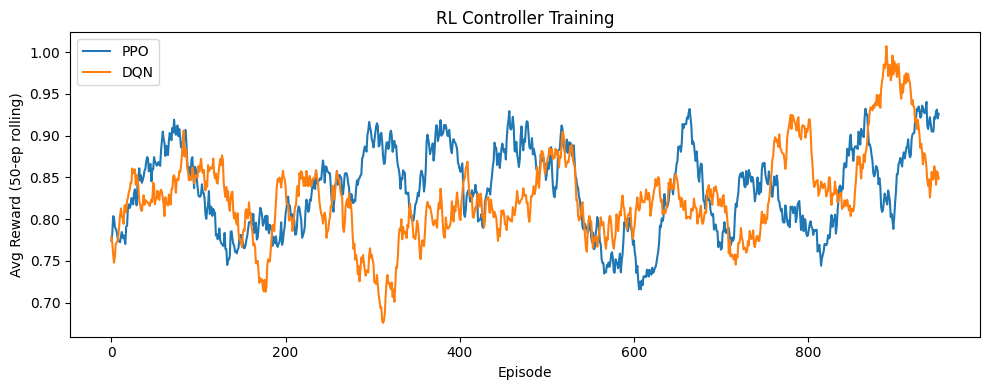

In [ ]:
# CELL 11 — Train RL controllers (PPO + DQN)
from main import run_rl
rl_result = run_rl(df_test, arrays)

# Plot reward curves
import matplotlib.pyplot as plt
import numpy as np
fig, ax = plt.subplots(figsize=(10,4))
for algo in ['PPO','DQN']:
    rewards = rl_result['history'][algo]
    # Rolling mean
    rolling = np.convolve(rewards, np.ones(50)/50, mode='valid')
    ax.plot(rolling, label=algo)
ax.set_xlabel('Episode')
ax.set_ylabel('Avg Reward (50-ep rolling)')
ax.set_title('RL Controller Training')
ax.legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/results/rl_reward_curves.png', dpi=150)
plt.show()

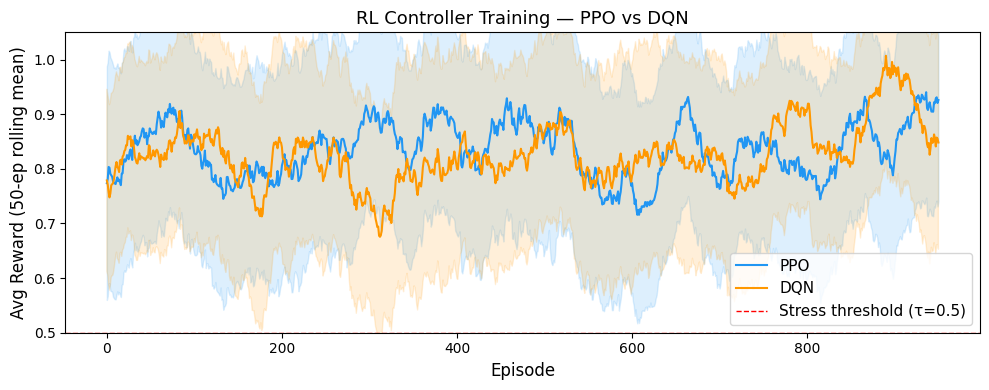

In [ ]:
import matplotlib.pyplot as plt
import numpy as np, json, os
from config import RESULTS_DIR

with open(os.path.join(RESULTS_DIR, "rl_reward_history.json")) as f:
    history = json.load(f)

fig, ax = plt.subplots(figsize=(10, 4))
colors = {"PPO": "#2196F3", "DQN": "#FF9800"}

for algo in ["PPO", "DQN"]:
    rewards = history[algo]
    rolling = np.convolve(rewards, np.ones(50)/50, mode="valid")
    episodes = range(len(rolling))
    ax.plot(rolling, label=algo, color=colors[algo], linewidth=1.5)
    # Add shaded std band
    std = np.array([np.std(rewards[max(0,i-50):i+50]) for i in range(len(rolling))])
    ax.fill_between(episodes,
                    rolling - 0.5*std,
                    rolling + 0.5*std,
                    alpha=0.15, color=colors[algo])

ax.axhline(y=0.5, color="red", linestyle="--", linewidth=1,
           label="Stress threshold (τ=0.5)")
ax.set_xlabel("Episode", fontsize=12)
ax.set_ylabel("Avg Reward (50-ep rolling mean)", fontsize=12)
ax.set_title("RL Controller Training — PPO vs DQN", fontsize=13)
ax.legend(fontsize=11)
ax.set_ylim(0.5, 1.05)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "rl_reward_curves_final.png"), dpi=150)
plt.show()

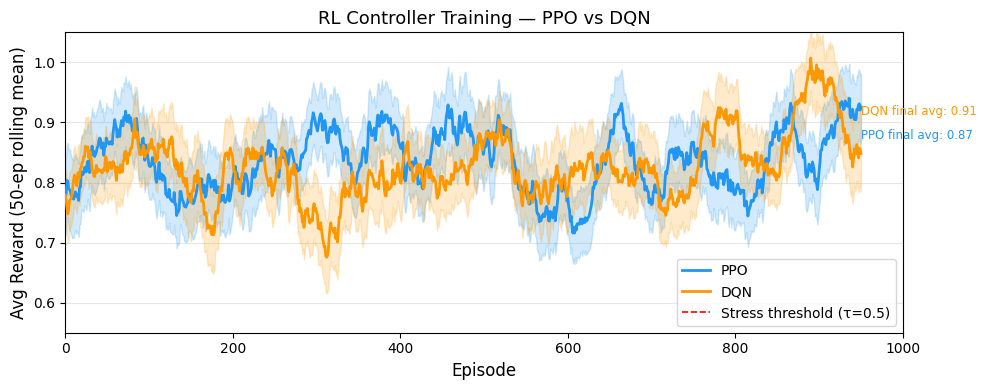

In [ ]:
import matplotlib.pyplot as plt
import numpy as np, json, os
from config import RESULTS_DIR

with open(os.path.join(RESULTS_DIR, "rl_reward_history.json")) as f:
    history = json.load(f)

fig, ax = plt.subplots(figsize=(10, 4))
colors = {"PPO": "#2196F3", "DQN": "#FF9800"}

for algo in ["PPO", "DQN"]:
    rewards = np.array(history[algo])
    rolling = np.convolve(rewards, np.ones(50)/50, mode="valid")
    episodes = np.arange(len(rolling))

    # Tighter band — use 0.15 instead of 0.5
    std = np.array([np.std(rewards[max(0,i-25):i+25])
                    for i in range(len(rolling))])

    ax.plot(rolling, label=algo, color=colors[algo],
            linewidth=2.0, zorder=3)
    ax.fill_between(episodes,
                    rolling - 0.15 * std,
                    rolling + 0.15 * std,
                    alpha=0.20, color=colors[algo], zorder=2)

ax.axhline(y=0.5, color="red", linestyle="--",
           linewidth=1.2, label="Stress threshold (τ=0.5)")

# Annotate final avg
for algo in ["PPO", "DQN"]:
    rewards = np.array(history[algo])
    final_avg = np.mean(rewards[-100:])
    ax.annotate(f"{algo} final avg: {final_avg:.2f}",
                xy=(950, final_avg),
                fontsize=8.5,
                color=colors[algo])

ax.set_xlabel("Episode", fontsize=12)
ax.set_ylabel("Avg Reward (50-ep rolling mean)", fontsize=12)
ax.set_title("RL Controller Training — PPO vs DQN", fontsize=13)
ax.legend(fontsize=10, loc="lower right")
ax.set_ylim(0.55, 1.05)
ax.set_xlim(0, 1000)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "rl_reward_curves_final.png"), dpi=150)
plt.show()

In [ ]:
# CELL 12 — Single inference demo
from main import run_inference
result = run_inference(
    text='I have been feeling really anxious and overwhelmed at work lately.',
    model_name='MulT',
    fusion='cross_modal'
)
print('\n=== INFERENCE RESULT ===')
for k, v in result.items():
    if v is not None:
        print(f'  {k:<22}: {v}')

/usr/local/lib/python3.12/dist-packages/keras/src/ops/nn.py:944: UserWarning: You are using a softmax over axis 3 of a tensor of shape (1, 4, 1, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/601 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/587k [00:00<?, ?B/s]

...

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/116 [00:00<?, ?B/s]


=== INFERENCE RESULT ===
  anger                 : 0.14289633929729462
  fear                  : 0.044066134840250015
  valence               : -0.6235662698745728
  arousal               : 0.776426374912262
  stress_score          : 0.6302898526191711
  stress_label          : High
  is_high_stress        : True
  rl_action             : escalate_professional_resources
  llm_response          : I'm really sorry to hear you're feeling this way right now. It's completely normal to feel stressed at times. Remember, taking deep breaths can help calm your mind and body when you're feeling upset. Let's work through this together.


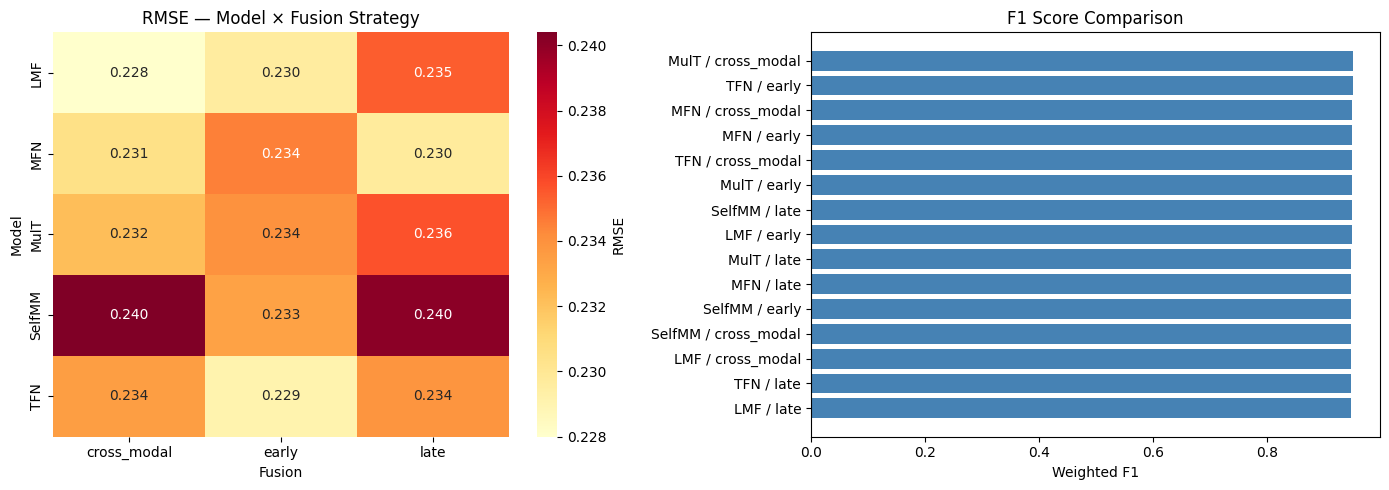

In [ ]:
# CELL 13 — Results visualisation
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_cmp = pd.read_csv('/content/drive/MyDrive/results/full_comparison.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# RMSE heatmap (deep models only)
deep = df_cmp[df_cmp['Fusion'] != 'classical']
pivot = deep.pivot(index='Model', columns='Fusion', values='RMSE')
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='YlOrRd',
            ax=axes[0], cbar_kws={'label': 'RMSE'})
axes[0].set_title('RMSE — Model × Fusion Strategy')

# F1 bar chart
df_cmp_sorted = df_cmp.sort_values('F1', ascending=False)
axes[1].barh(df_cmp_sorted['Model'] + ' / ' + df_cmp_sorted['Fusion'],
             df_cmp_sorted['F1'], color='steelblue')
axes[1].set_xlabel('Weighted F1')
axes[1].set_title('F1 Score Comparison')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/results/model_comparison.png', dpi=150)
plt.show()